In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif

In [2]:
df = pd.read_csv("diabetes.csv")

In [3]:
print("="*60)
print("Dataset Shape")
print(df.shape)

Dataset Shape
(768, 9)


In [4]:
print("="*60)
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [5]:
print("="*60)
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


In [6]:
print("="*60)
print(df.describe())

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

In [7]:
print("="*60)
print("Missing Values")
print(df.isnull().sum())

Missing Values
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [8]:
print("="*60)
print("Duplicate Rows:",df.duplicated().sum())

Duplicate Rows: 0


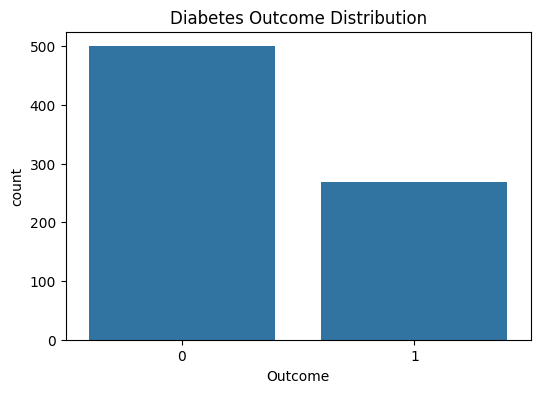

Outcome
0    500
1    268
Name: count, dtype: int64


In [9]:
plt.figure(figsize=(6,4))
sns.countplot(x='Outcome',data=df)
plt.title("Diabetes Outcome Distribution")
plt.show()

print(df['Outcome'].value_counts())

In [10]:
num_cols=df.select_dtypes(include=np.number).columns
print("\nNumerical Features")
print(num_cols)


Numerical Features
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


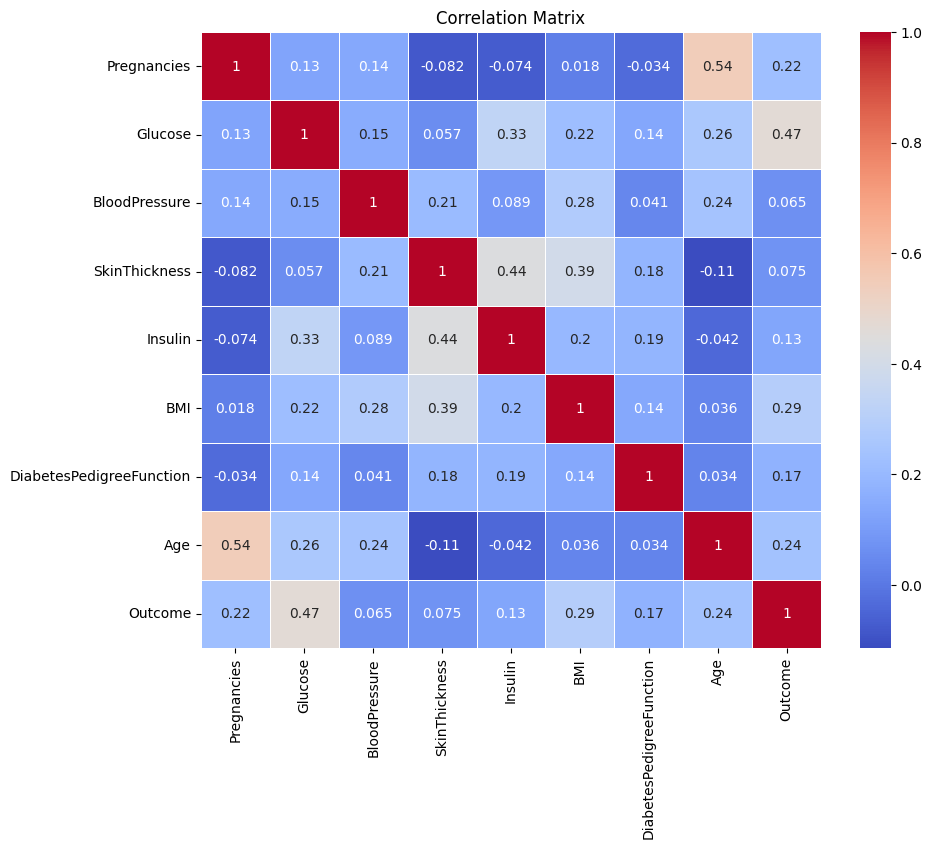

In [11]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(),annot=True,cmap='coolwarm',linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()

In [12]:
corr=df.corr()['Outcome'].sort_values(ascending=False)

print("\nCorrelation with Outcome")
print(corr)


Correlation with Outcome
Outcome                     1.000000
Glucose                     0.466581
BMI                         0.292695
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
Insulin                     0.130548
SkinThickness               0.074752
BloodPressure               0.065068
Name: Outcome, dtype: float64


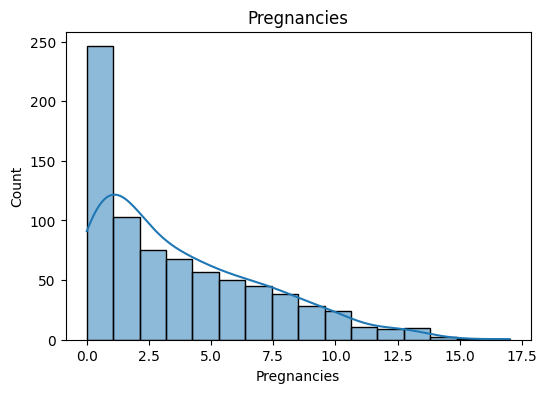

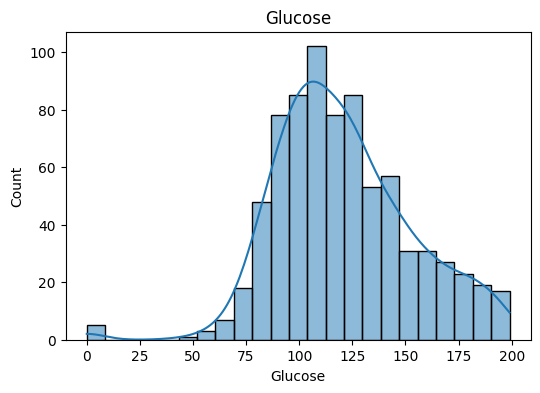

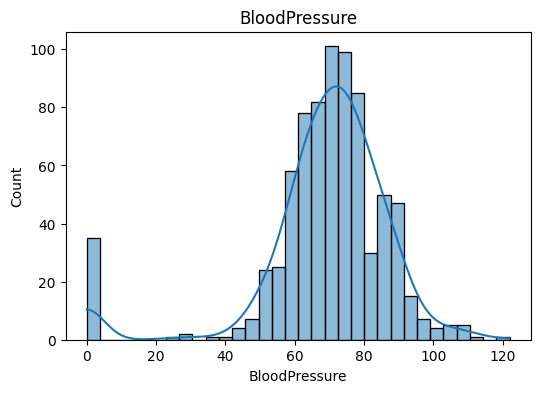

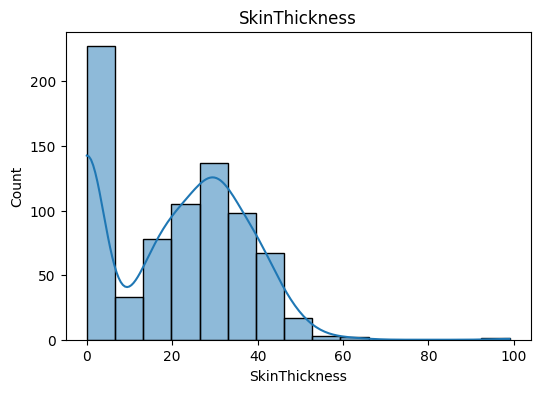

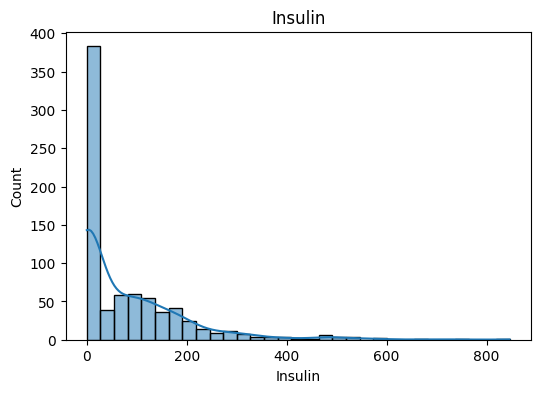

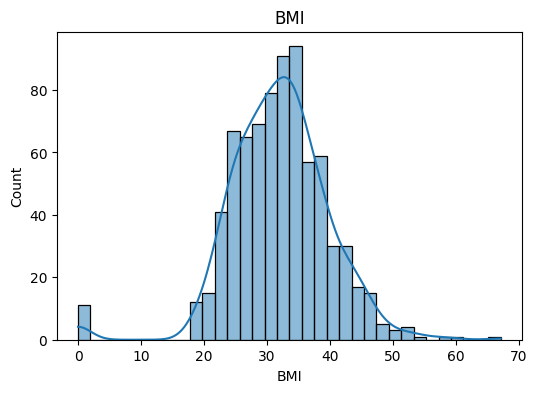

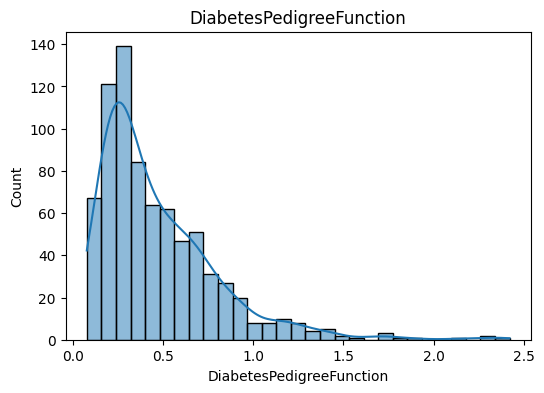

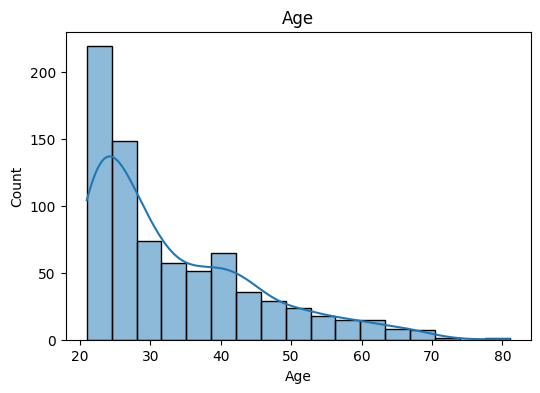

In [13]:
for col in num_cols[:-1]:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col],kde=True)
    plt.title(col)
    plt.show()

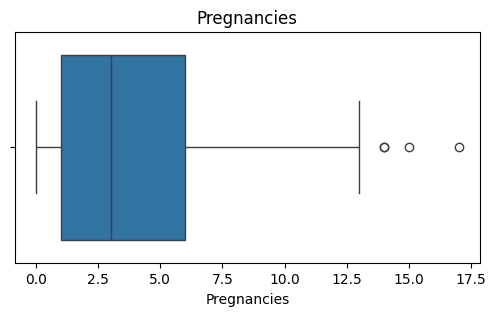

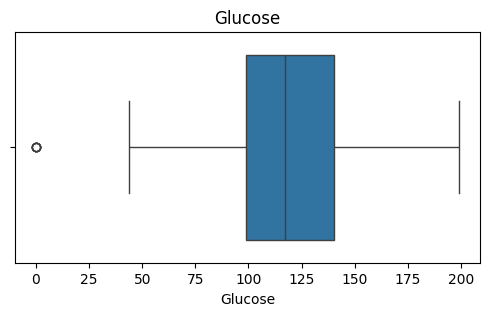

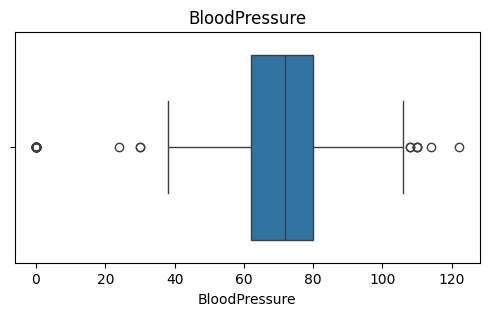

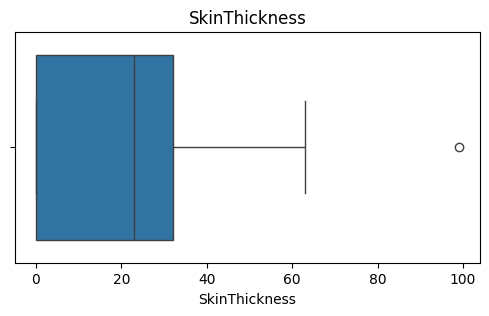

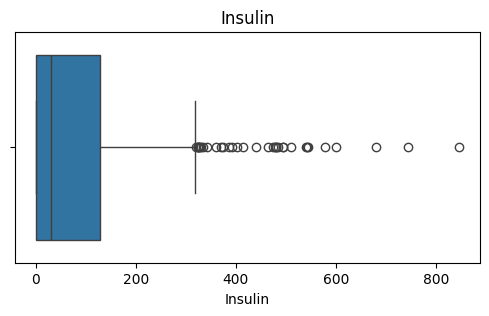

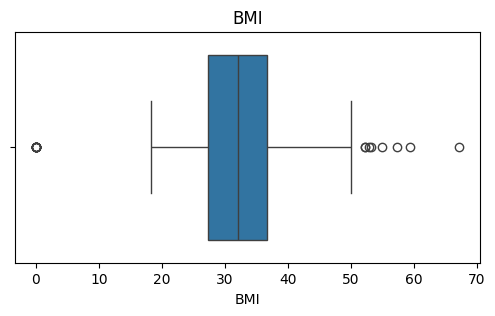

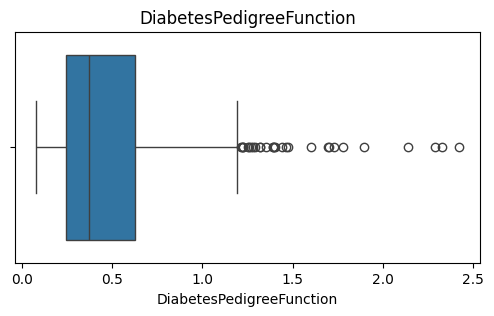

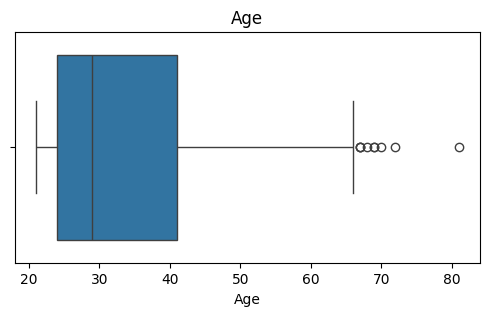

In [14]:
for col in num_cols[:-1]:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

In [15]:
print("="*60)

print("Feature Skewness")
print(df[num_cols].skew().sort_values(ascending=False))

Feature Skewness
Insulin                     2.272251
DiabetesPedigreeFunction    1.919911
Age                         1.129597
Pregnancies                 0.901674
Outcome                     0.635017
Glucose                     0.173754
SkinThickness               0.109372
BMI                        -0.428982
BloodPressure              -1.843608
dtype: float64


In [16]:
zero_columns=[
    'Glucose','BloodPressure','SkinThickness','Insulin','BMI']

In [17]:
for col in zero_columns:
    print(f"{col}Zero Values :{(df[col]==0).sum()}")

GlucoseZero Values :5
BloodPressureZero Values :35
SkinThicknessZero Values :227
InsulinZero Values :374
BMIZero Values :11


In [18]:
for col in zero_columns:
    df[col]=df[col].replace(0,np.nan)
    df[col]=df[col].fillna(df[col].median())

In [19]:
df['AgeGroup']=pd.cut(df['Age'],
                      bins=[20,30,40,50,60,100],
                      labels=[0,1,2,3,4])

df['BMI_Category']=pd.cut(df['BMI'],
                          bins=[0,18.5,25,30,100],
                          labels=[0,1,2,3])

df['Glucose_Level']=pd.cut(df['Glucose'],
                           bins=[0,100,125,300],
                           labels=[0,1,2])

df['AgeGroup']=df['AgeGroup'].astype(int)
df['BMI_Category']=df['BMI_Category'].astype(int)
df['Glucose_Level']=df['Glucose_Level'].astype(int)

In [20]:
X=df.drop("Outcome",axis=1)
y=df["Outcome"]

scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [21]:
selector=SelectKBest(score_func=f_classif,k=8)

X_selected=selector.fit_transform(X_scaled,y)
selected_features=X.columns[selector.get_support()]
print("="*60)
print("Selected Features")
print(selected_features)

Selected Features
Index(['Pregnancies', 'Glucose', 'SkinThickness', 'BMI', 'Age', 'AgeGroup',
       'BMI_Category', 'Glucose_Level'],
      dtype='object')


In [22]:
scores=pd.DataFrame({'Feature':X.columns,'Score':selector.scores_})
scores=scores.sort_values(by='Score',ascending=False)

print(scores)

                     Feature       Score
1                    Glucose  245.667855
10             Glucose_Level  176.492156
5                        BMI   82.629271
9               BMI_Category   80.047878
7                        Age   46.140611
8                   AgeGroup   45.132449
0                Pregnancies   39.670227
3              SkinThickness   37.078538
4                    Insulin   33.190796
6   DiabetesPedigreeFunction   23.871300
2              BloodPressure   21.631580


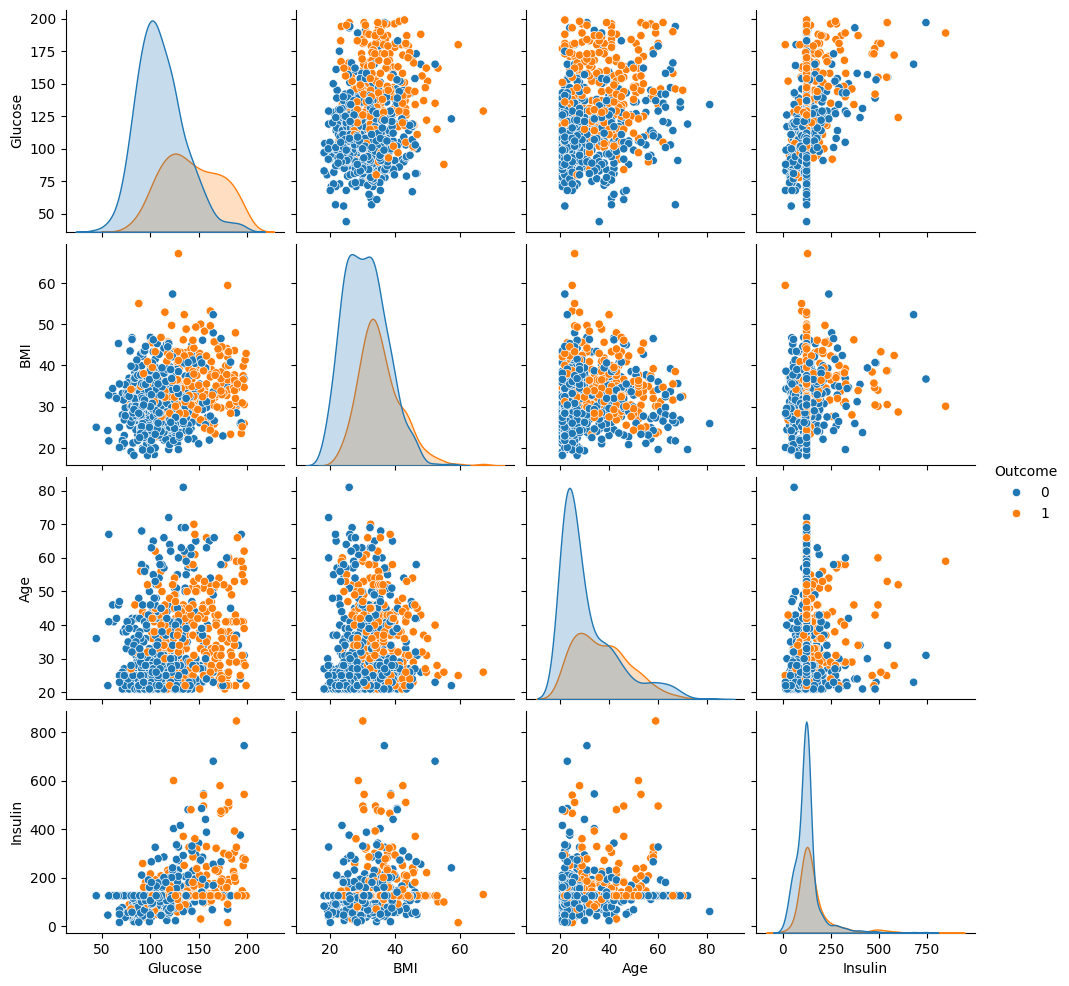

In [23]:
sns.pairplot(
df[['Glucose','BMI','Age','Insulin','Outcome']],
hue='Outcome'
)

plt.show()